In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset
from src.fdlbiomass.utils import load_biomass_data 
from src.fdlbiomass.dataloader_fns import check_pol_channels 
from src.fdlbiomass.utils import merge_headings , load_biomass_data, split_into_quadrants, crop_to_non_nan

Starting to load the biomass data
Load complete
Original shape: (326, 840)
Cropped shape: (321, 665)
665 665
Quadrant shape: torch.Size([160, 332, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 332]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([160, 333, 36, 1]) -> torch.Size([160, 336, 36, 1])
Ground truth shape: torch.Size([160, 333]) -> torch.Size([160, 336])
Quadrant shape: torch.Size([161, 332, 36, 1]) -> torch.Size([168, 336, 36, 1])
Ground truth shape: torch.Size([161, 332]) -> torch.Size([168, 336])
Quadrant shape: torch.Size([161, 333, 36, 1]) -> torch.Size([168, 336, 36, 1])
Ground truth shape: torch.Size([161, 333]) -> torch.Size([168, 336])
Total valid patches: 2344
Quadrant 0: 529 valid patches
Quadrant 1: 770 valid patches
Quadrant 2: 571 valid patches
Quadrant 3: 474 valid patches
Dataset Initialization Information:
Patch size: (16, 16, 36)
Stride: (8, 8, 36)

Quadrant 0:
  Original shape: torch.Size([160, 332, 36, 1])
  Padded sha

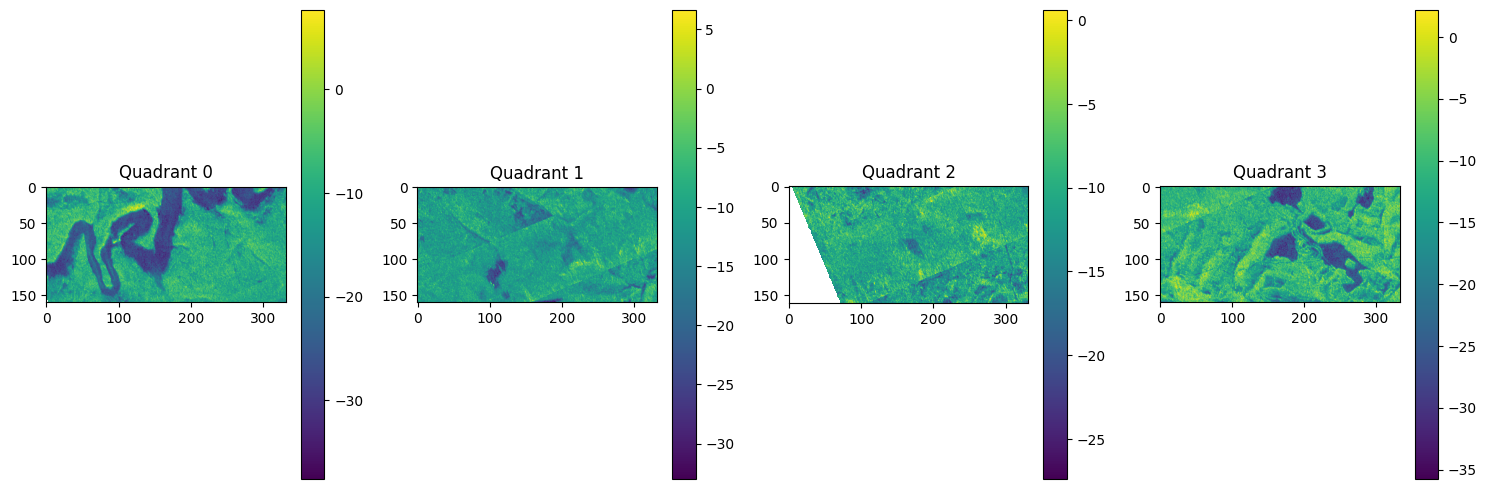

In [78]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from src.fdlbiomass.utils import merge_headings, load_biomass_data, split_into_quadrants, crop_to_non_nan
from src.fdlbiomass.quadrant_dataset_pband import QuadrantPatchDataset
from torch.utils.data import DataLoader
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.dataloader_fns import generate_quadrants, generate_dataloaders
# Assuming the necessary imports from your scripts

parent_path = '/home/grace.bcolverd/esl_dev/tomosar-matlab'
polarimetric_channels = 'HV'
patch_size = (16, 16, 36)
stride = (8, 8, 36)
test_quadrant = 3
batch_size = 4
scaler_type = 'minmax'

quadrants, ground_truths, num_channels = generate_quadrants(parent_path, polarimetric_channels)

# 2. Create dataset and dataloaders
train_loader, test_loader, val_loader, dataset, (input_scaler, gt_scaler), val_quad = generate_dataloaders(
    quadrants, ground_truths, patch_size, stride, test_quadrant, batch_size, scaler_type
)

# 3. Visualize original data
plt.figure(figsize=(15, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(quadrants[i][:,:,0,0])  # Assuming first channel, first depth slice
    plt.title(f"Quadrant {i}")
    plt.colorbar()
plt.tight_layout()
plt.show()

In [4]:
crop_int.shape

(321, 665, 36, 1)

In [5]:
cropped_LidarCHM.shape

(321, 665)

In [68]:
from src.fdlbiomass.image_reconstruction import * 

In [79]:
from src.fdlbiomass.simple_unet import simple_UNet3D2


def load_model(model_class, model_path, device,in_channels):
    """
    Load a PyTorch model from a saved path.

    :param model_class: The class of the model architecture
    :param model_path: Path to the saved model file
    :param device: The device to load the model on ('cpu' or 'cuda')
    :return: Loaded model
    """
    use_batchnorm='yes'
    dropout_rate=0.1
    z_collapse_method='conv'
    out_channels=1
    
    
    # Initialize the model architecture
    model = model_class(in_channels,  out_channels, use_batchnorm, dropout_rate, z_collapse_method)
    
    # Load the state dict
    state_dict = torch.load(model_path, map_location=device)
    
    # Load the state dict into the model
    model.load_state_dict(state_dict)
    
    # Move the model to the specified device
    model = model.to(device)
    
    # Set the model to evaluation mode
    model.eval()
    
    return model

model_path = '/home/grace.bcolverd/local/unet_model2/simple_unet2_bs4_lr0.0001_polchHV_testquad3_geosplitquadrant_ps(16, 16, 36)_str(8, 8, 36)_scaler:minmax_batchnormyes_dropout0.1_lossmse_zcolconv_simple_unet2_chm_model.pth'
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device = torch.device( 'cpu')
in_channels =1 
MODEL = load_model(simple_UNet3D2, model_path, device, in_channels)



In [109]:
from src.fdlbiomass.image_reconstruction import * 

In [110]:

# Main process
cube_shape = (321, 665, 36)
patch_size = (16, 16, 36)  # or (32, 32, 36)


# Create patches
patches, patch_info, padding_info = create_patches(crop_int[:,:,:,0], patch_size)

In [111]:
predictions = process_patches(patches, MODEL, input_scaler, gt_scaler)


Patch 0 shape: (16, 16, 36)
Patch 1 shape: (16, 16, 36)
Patch 2 shape: (16, 16, 36)
Patch 3 shape: (16, 16, 36)
Patch 4 shape: (16, 16, 36)
Patch 5 shape: (16, 16, 36)
Patch 6 shape: (16, 16, 36)
Patch 7 shape: (16, 16, 36)
Patch 8 shape: (16, 16, 36)
Patch 9 shape: (16, 16, 36)
Patch 10 shape: (16, 16, 36)
Patch 11 shape: (16, 16, 36)
Patch 12 shape: (16, 16, 36)
Patch 13 shape: (16, 16, 36)
Patch 14 shape: (16, 16, 36)
Patch 15 shape: (16, 16, 36)
Patch 16 shape: (16, 16, 36)
Patch 17 shape: (16, 16, 36)
Patch 18 shape: (16, 16, 36)
Patch 19 shape: (16, 16, 36)
Patch 20 shape: (16, 16, 36)
Patch 21 shape: (16, 16, 36)
Patch 22 shape: (16, 16, 36)
Patch 23 shape: (16, 16, 36)
Patch 24 shape: (16, 16, 36)
Patch 25 shape: (16, 16, 36)
Patch 26 shape: (16, 16, 36)
Patch 27 shape: (16, 16, 36)
Patch 28 shape: (16, 16, 36)
Patch 29 shape: (16, 16, 36)
Patch 30 shape: (16, 16, 36)
Patch 31 shape: (16, 16, 36)
Patch 32 shape: (16, 16, 36)
Patch 33 shape: (16, 16, 36)
Patch 34 shape: (16, 16,

In [114]:
patch_info

(21, 42, 36)

: 

321 665
16 16


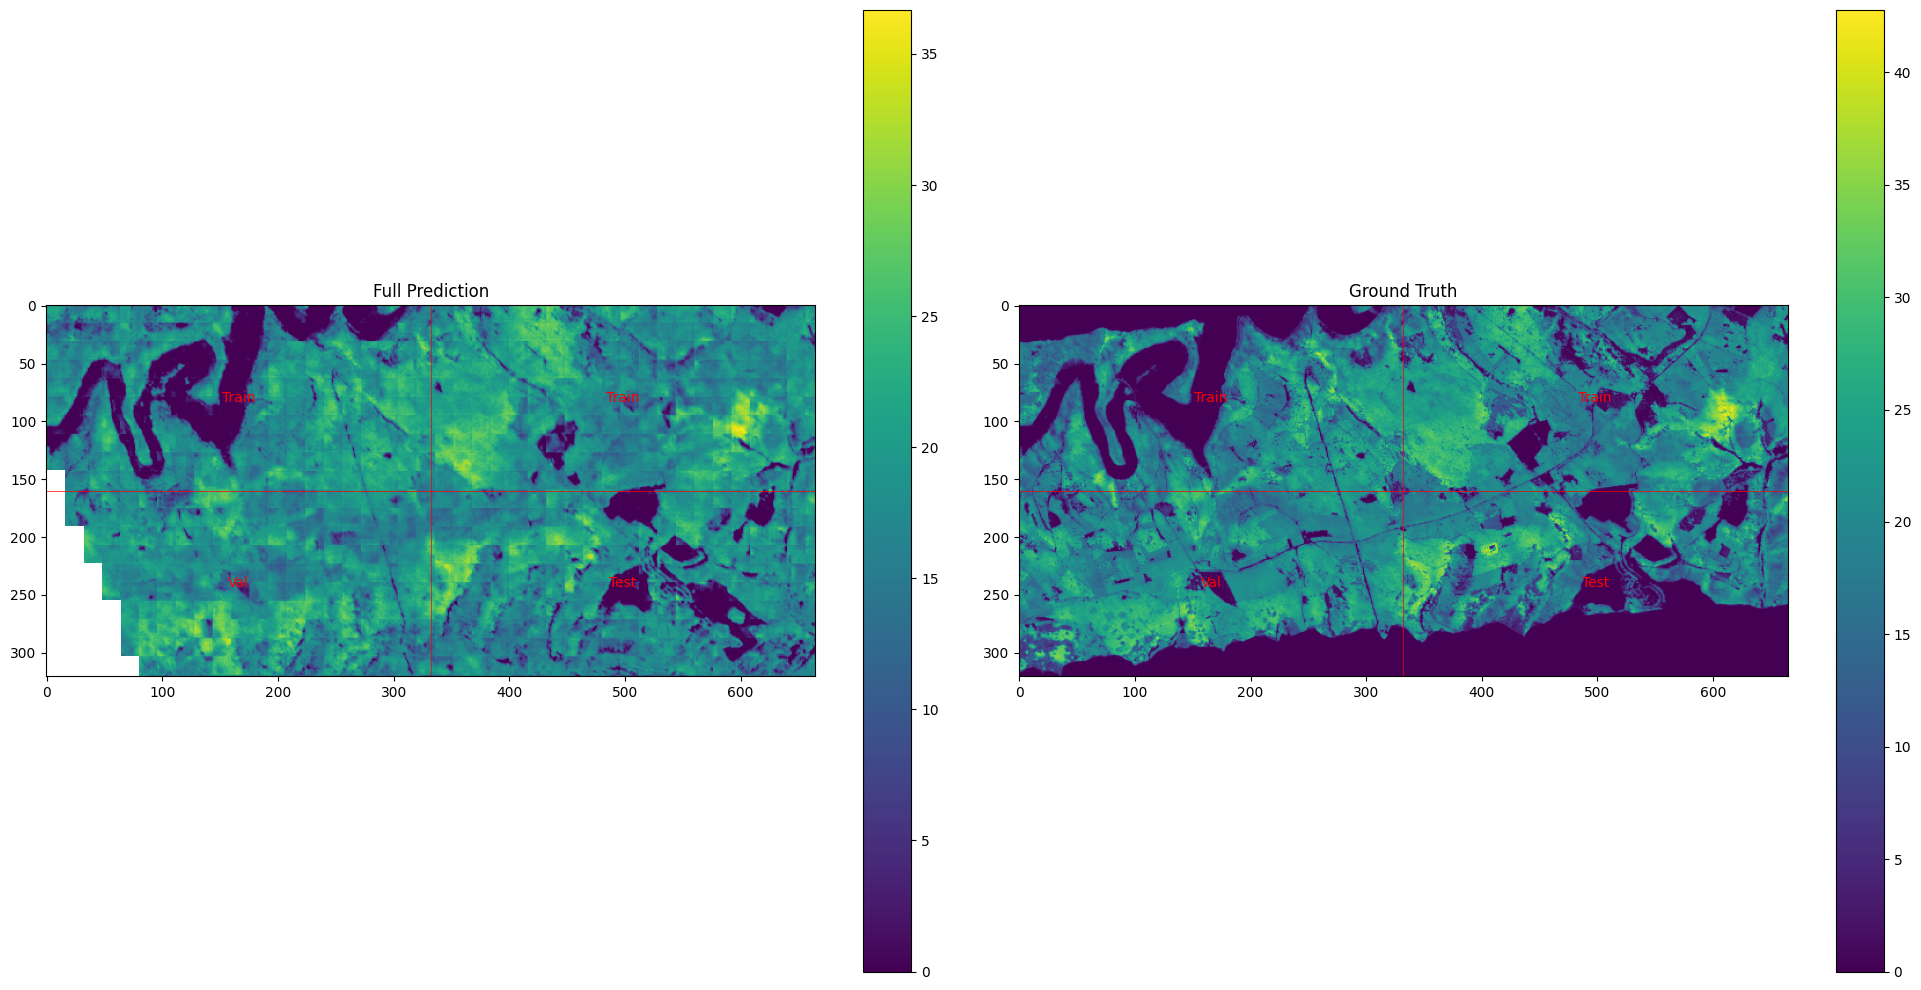

Mean Absolute Error: nan
Quadrant MAE - Train (top-left): nan
Quadrant MAE - Train (top-right): 3.7676
Quadrant MAE - Val (bottom-left): nan
Quadrant MAE - Test (bottom-right): 6.9818


In [113]:
# Use the function
# Reconstruct full prediction
full_prediction = reconstruct_prediction(predictions, cube_shape, patch_info, padding_info)
ground_truth = cropped_LidarCHM
visualize_with_quadrants(full_prediction, cropped_LidarCHM, cube_shape)

In [83]:
ground_truth = cropped_LidarCHM

In [105]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_with_quadrants(full_prediction, ground_truth, cube_shape):
    # Ensure ground truth and prediction have the same shape
    min_height = min(full_prediction.shape[0], ground_truth.shape[0])
    min_width = min(full_prediction.shape[1], ground_truth.shape[1])

    full_prediction = full_prediction[:min_height, :min_width]
    ground_truth = ground_truth[:min_height, :min_width]

    # Calculate error
    error = np.abs(full_prediction - ground_truth)

    # Calculate quadrant boundaries
    height, width = full_prediction.shape
    mid_h, mid_w = height // 2, width // 2

    # Visualize the full prediction, ground truth, and error
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(24, 8))
    fig.suptitle("Prediction, Ground Truth, and Absolute Error", fontsize=16)

    # Plot prediction
    im1 = ax1.imshow(full_prediction, cmap='viridis', aspect='auto')
    ax1.set_title("Full Prediction", fontsize=14)
    cbar1 = plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    cbar1.ax.tick_params(labelsize=10)

    # Plot ground truth
    im2 = ax2.imshow(ground_truth, cmap='viridis', aspect='auto')
    ax2.set_title("Ground Truth", fontsize=14)
    cbar2 = plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    cbar2.ax.tick_params(labelsize=10)

    # Plot error
    im3 = ax3.imshow(error, cmap='hot', aspect='auto')
    ax3.set_title("Absolute Error", fontsize=14)
    cbar3 = plt.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)
    cbar3.ax.tick_params(labelsize=10)

    # Add quadrant lines and labels to all plots
    for ax in [ax1, ax2, ax3]:
        ax.axhline(y=mid_h, color='r', linestyle='-', linewidth=0.5)
        ax.axvline(x=mid_w, color='r', linestyle='-', linewidth=0.5)

        fontsize = 20
        ax.text(mid_w/2, mid_h/2, 'Train', color='white', ha='center', va='center', fontsize=fontsize, fontweight='bold')
        ax.text(mid_w*1.5, mid_h/2, 'Train', color='white', ha='center', va='center', fontsize=fontsize, fontweight='bold')
        ax.text(mid_w/2, mid_h*1.5, 'Val', color='white', ha='center', va='center', fontsize=fontsize, fontweight='bold')
        ax.text(mid_w*1.5, mid_h*1.5, 'Test', color='white', ha='center', va='center', fontsize=fontsize, fontweight='bold')

        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()

    # Calculate and print Mean Absolute Error
    mae = np.mean(error)
    print(f"\nOverall Mean Absolute Error: {mae:.4f}")

    # Calculate and print Mean Absolute Error for each quadrant
    quadrant_names = ['Train (top-left)', 'Train (top-right)', 'Val (bottom-left)', 'Test (bottom-right)']
    for i in range(2):
        for j in range(2):
            quad_error = error[i*mid_h:(i+1)*mid_h, j*mid_w:(j+1)*mid_w]
            quad_mae = np.mean(quad_error)
            print(f"Quadrant MAE - {quadrant_names[i*2+j]}: {quad_mae:.4f}")

    return error

In [107]:

def visualize_with_quadrants(full_prediction, ground_truth, cube_shape):
    # Ensure ground truth and prediction have the same shape
    min_height = min(full_prediction.shape[0], ground_truth.shape[0])
    min_width = min(full_prediction.shape[1], ground_truth.shape[1])

    full_prediction = full_prediction[:min_height, :min_width]
    ground_truth = ground_truth[:min_height, :min_width]

    # Calculate error
    error = np.abs(full_prediction - ground_truth)

    # Calculate quadrant boundaries
    height, width = full_prediction.shape
    mid_h, mid_w = height // 2, width // 2

    # Visualize the full prediction, ground truth, and error
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(30, 10))
    fs = 10 
    # Plot prediction
    im1 = ax1.imshow(full_prediction, cmap='viridis')
    ax1.set_title("Full Prediction")
    plt.colorbar(im1, ax=ax1)

    # Plot ground truth
    im2 = ax2.imshow(ground_truth, cmap='viridis')
    ax2.set_title("Ground Truth")
    plt.colorbar(im2, ax=ax2,fraction=0.046, pad=0.04)

    # Plot error
    im3 = ax3.imshow(error, cmap='hot')
    ax3.set_title("Absolute Error")
    plt.colorbar(im3, ax=ax3)

    # Add quadrant lines and labels to all plots
    for ax in [ax1, ax2, ax3]:
        ax.axhline(y=mid_h, color='r', linestyle='-', linewidth=0.5)
        ax.axvline(x=mid_w, color='r', linestyle='-', linewidth=0.5)

        ax.text(mid_w/2, mid_h/2, 'Train', color='red', ha='center', va='center', fontsize =fs)
        ax.text(mid_w*1.5, mid_h/2, 'Train', color='red', ha='center', va='center', fontsize =fs)
        ax.text(mid_w/2, mid_h*1.5, 'Val', color='red', ha='center', va='center', fontsize =fs)
        ax.text(mid_w*1.5, mid_h*1.5, 'Test', color='red', ha='center', va='center', fontsize =fs )

    plt.tight_layout()
    plt.show()

    # Calculate and print Mean Absolute Error
    mae = np.mean(error)
    print(f"Overall Mean Absolute Error: {mae:.4f}")

    # Calculate and print Mean Absolute Error for each quadrant
    quad_mae = []
    quadrant_names = ['Train (top-left)', 'Train (top-right)', 'Val (bottom-left)', 'Test (bottom-right)']
    for i in range(2):
        for j in range(2):
            quad_error = error[i*mid_h:(i+1)*mid_h, j*mid_w:(j+1)*mid_w]
            quad_mae = np.mean(quad_error)
            print(f"Quadrant MAE - {quadrant_names[i*2+j]}: {quad_mae:.4f}")

    return error

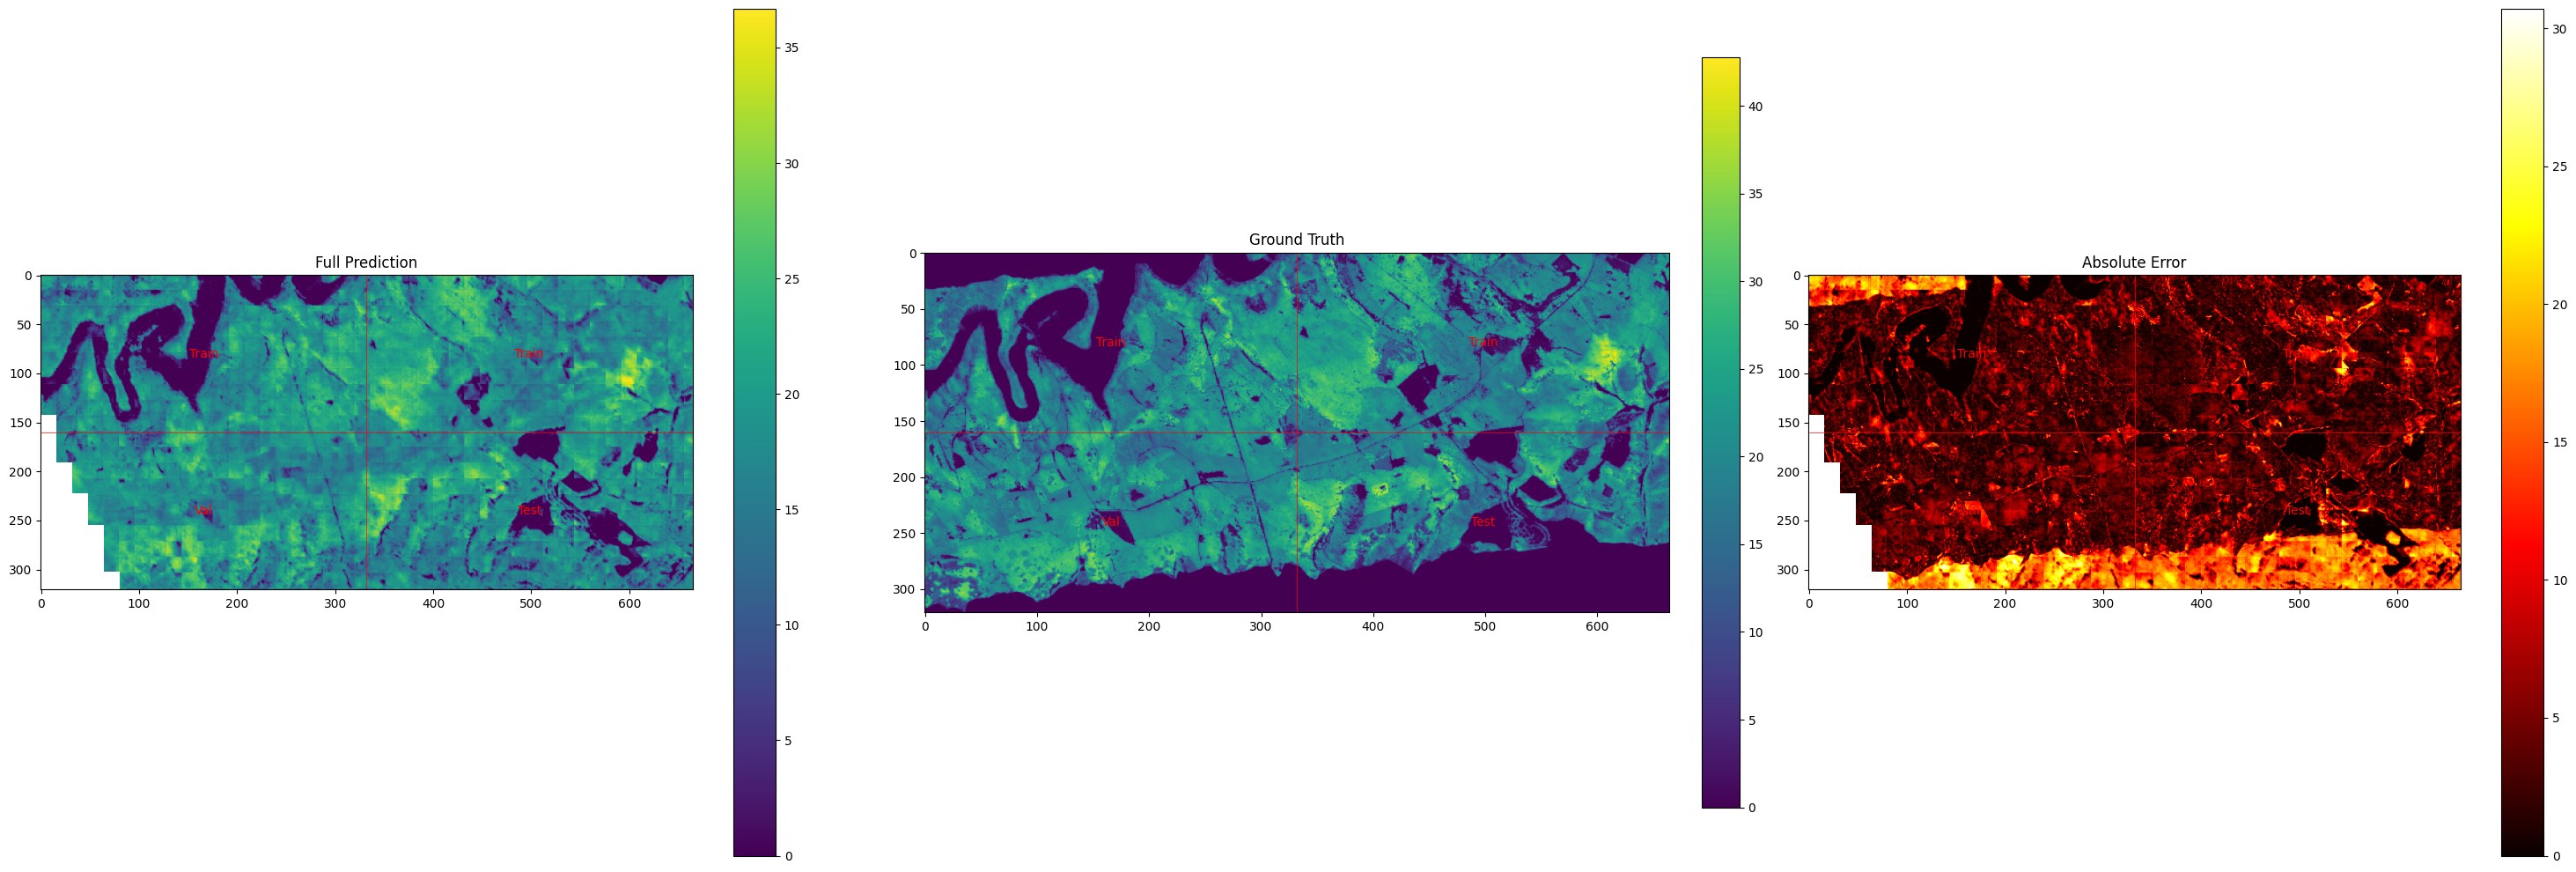

Overall Mean Absolute Error: nan
Quadrant MAE - Train (top-left): nan
Quadrant MAE - Train (top-right): 3.7676
Quadrant MAE - Val (bottom-left): nan
Quadrant MAE - Test (bottom-right): 6.9818


In [108]:
error = visualize_with_quadrants(full_prediction, cropped_LidarCHM, cube_shape)